In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [6]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [7]:
df = df.drop("customerID", axis=1)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


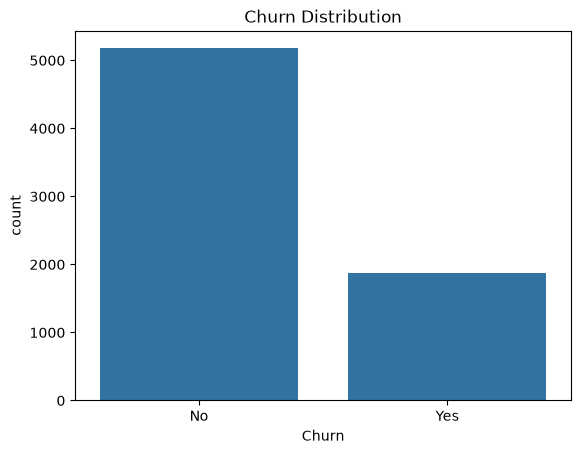

In [8]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)

sns.countplot(x="Churn", data=df)
plt.title("Churn Distribution")
plt.show()

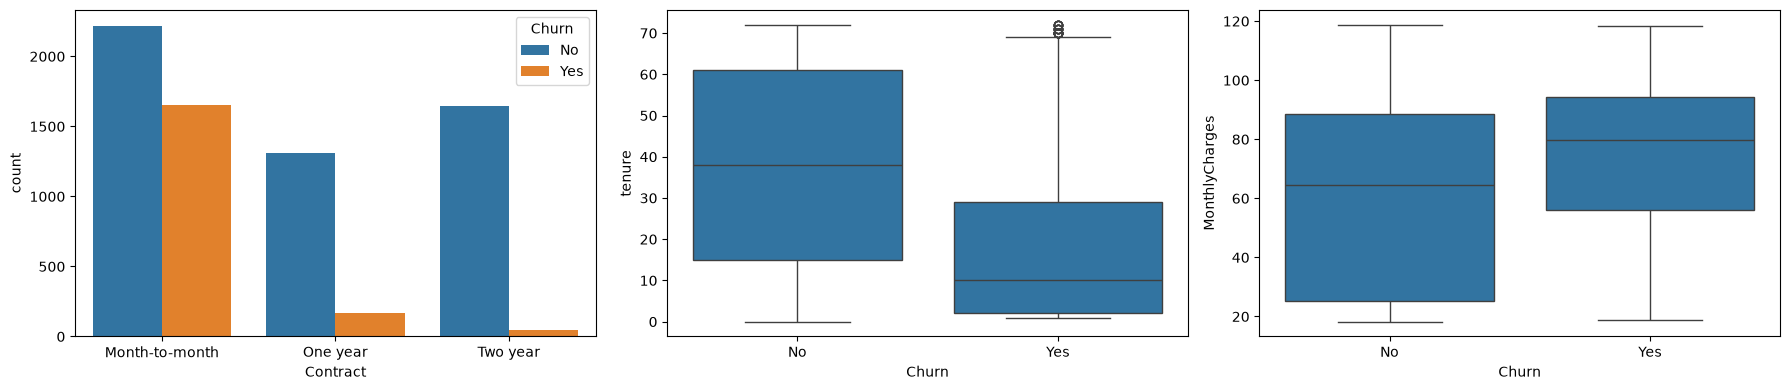

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

sns.countplot(x="Contract", hue="Churn", data=df, ax=axes[0])
sns.boxplot(x="Churn", y="tenure", data=df, ax=axes[1])
sns.boxplot(x="Churn", y="MonthlyCharges", data=df, ax=axes[2])

plt.tight_layout()
plt.show()

In [10]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
print(cat_cols)

for col in cat_cols:
    print(col, "->", df[col].unique())

['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']
gender -> <ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str
Partner -> <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
Dependents -> <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
PhoneService -> <ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str
MultipleLines -> <ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str
InternetService -> <ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str
OnlineSecurity -> <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
OnlineBackup -> <ArrowStringArray>
['Yes', 'No', 'No internet service']
Length: 3, dtype: str
DeviceProtection -> <ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str
TechSu

C:\Users\Administrator\AppData\Local\Temp\ipykernel_1248\3008244729.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist()


In [11]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

In [12]:
df_encoded = pd.get_dummies(df, drop_first=True)
print("Shape:", df_encoded.shape)
df_encoded.head()

Shape: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,False,True,False,False,True,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,True,False,False,True,False,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,True,False,False,False,True,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,False,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False


In [13]:
X = df_encoded.drop("Churn", axis=1)
y = df_encoded["Churn"]
print(X.shape, y.shape)

(7043, 30) (7043,)


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)
print("Train churn %:", y_train.mean() * 100)
print("Test churn %:", y_test.mean() * 100)

Train: (5634, 30)
Test: (1409, 30)
Train churn %: 26.53532126375577
Test churn %: 26.54364797728886


In [15]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,-0.00,-0.00,0.00
std,1.00,1.00,1.00
min,-1.32,-1.54,-1.01
25%,-0.96,-0.97,-0.83
50%,-0.14,0.18,-0.40
75%,0.92,0.83,0.67
max,1.61,1.79,2.80


In [16]:
import joblib, os

os.makedirs("../models", exist_ok=True)
joblib.dump(scaler, "../models/scaler.pkl")
joblib.dump(X.columns.tolist(), "../models/feature_columns.pkl")

['../models/feature_columns.pkl']

In [17]:
X_train = X_train.astype("float32")
X_test = X_test.astype("float32")
y_train = y_train.astype("float32")
y_test = y_test.astype("float32")

print(X_train.dtypes.value_counts())

float32    30
Name: count, dtype: int64


In [18]:
from sklearn.preprocessing import StandardScaler

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

X_train[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,5634.00,5634.00,5634.00
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-1.32,-1.54,-1.01
25%,-0.96,-0.97,-0.83
50%,-0.14,0.18,-0.40
75%,0.92,0.83,0.67
max,1.61,1.79,2.80


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.05, max_depth=4, random_state=42, eval_metric="logloss"),
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })

results_df = pd.DataFrame(results).round(3)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.807,0.660,0.561,0.607,0.842
1,Random Forest,0.790,0.629,0.508,0.562,0.826
2,XGBoost,0.799,0.651,0.524,0.581,0.844


In [20]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)

X_train_t = torch.tensor(X_train.values, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
X_test_t = torch.tensor(X_test.values, dtype=torch.float32)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)

print(X_train_t.shape, y_train_t.shape)

torch.Size([5634, 30]) torch.Size([5634, 1])


In [21]:
class ChurnANN(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 1)   # sigmoid yahan nahi, loss function me hai
        )

    def forward(self, x):
        return self.net(x)

model = ChurnANN(X_train_t.shape[1])

# Class imbalance handle: churn walon ko zyada weight
pos_weight = torch.tensor([(y_train == 0).sum() / (y_train == 1).sum()], dtype=torch.float32)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

In [22]:
from sklearn.metrics import roc_auc_score

best_auc, patience, wait = 0, 15, 0
best_state = None

for epoch in range(200):
    model.train()
    for xb, yb in train_loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        test_prob = torch.sigmoid(model(X_test_t)).numpy().ravel()
    auc = roc_auc_score(y_test, test_prob)

    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d} | loss {loss.item():.4f} | test AUC {auc:.4f}")

    if auc > best_auc:
        best_auc, wait = auc, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= patience:
            print(f"Early stopping at epoch {epoch}")
            break

model.load_state_dict(best_state)
print("Best AUC:", round(best_auc, 4))

Epoch   0 | loss 0.3969 | test AUC 0.8288
Epoch  10 | loss 0.4195 | test AUC 0.8445
Epoch  20 | loss 0.6870 | test AUC 0.8441
Early stopping at epoch 27
Best AUC: 0.8446


In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model.eval()
with torch.no_grad():
    prob = torch.sigmoid(model(X_test_t)).numpy().ravel()
pred = (prob >= 0.5).astype(int)

ann_result = {
    "Model": "ANN (PyTorch)",
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred),
    "Recall": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred),
    "ROC-AUC": roc_auc_score(y_test, prob),
}

results_df = pd.concat([results_df, pd.DataFrame([ann_result]).round(3)], ignore_index=True)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.807,0.660,0.561,0.607,0.842
1,Random Forest,0.790,0.629,0.508,0.562,0.826
2,XGBoost,0.799,0.651,0.524,0.581,0.844
3,ANN (PyTorch),0.731,0.496,0.834,0.622,0.845


In [24]:
torch.save(model.state_dict(), "../models/churn_ann.pt")
results_df.to_csv("../models/results.csv", index=False)

In [25]:
joblib.dump(models["XGBoost"], "../models/xgb_model.pkl")
joblib.dump(models["Logistic Regression"], "../models/logreg_model.pkl")

['../models/logreg_model.pkl']

In [26]:
print("Input dim:", X_train_t.shape[1])

Input dim: 30


    Threshold  Accuracy  Precision  Recall     F1
0        0.20     0.589      0.389   0.957  0.553
1        0.25     0.627      0.411   0.944  0.573
2        0.30     0.648      0.425   0.928  0.583
3        0.35     0.674      0.444   0.906  0.596
4        0.40     0.688      0.455   0.882  0.600
5        0.45     0.714      0.479   0.866  0.617
6        0.50     0.731      0.496   0.834  0.622
7        0.55     0.751      0.520   0.783  0.625
8        0.60     0.769      0.547   0.741  0.630
9        0.65     0.779      0.570   0.676  0.619
10       0.70     0.797      0.613   0.636  0.625
11       0.75     0.803      0.660   0.535  0.591
12       0.80     0.801      0.696   0.441  0.540


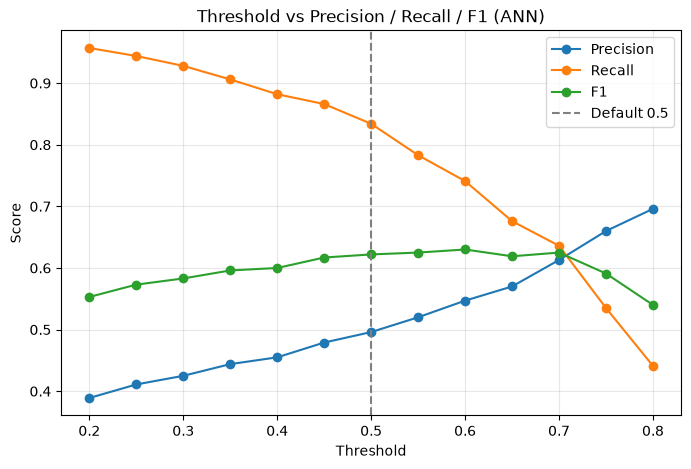

Best F1 threshold: 0.6


In [27]:
from sklearn.metrics import precision_recall_curve

thresholds = np.arange(0.2, 0.85, 0.05)
rows = []

for t in thresholds:
    pred_t = (prob >= t).astype(int)
    rows.append({
        "Threshold": round(t, 2),
        "Accuracy": accuracy_score(y_test, pred_t),
        "Precision": precision_score(y_test, pred_t, zero_division=0),
        "Recall": recall_score(y_test, pred_t),
        "F1": f1_score(y_test, pred_t),
    })

thr_df = pd.DataFrame(rows).round(3)
print(thr_df)

plt.figure(figsize=(8, 5))
plt.plot(thr_df["Threshold"], thr_df["Precision"], marker="o", label="Precision")
plt.plot(thr_df["Threshold"], thr_df["Recall"], marker="o", label="Recall")
plt.plot(thr_df["Threshold"], thr_df["F1"], marker="o", label="F1")
plt.axvline(0.5, color="gray", linestyle="--", label="Default 0.5")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold vs Precision / Recall / F1 (ANN)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

best_row = thr_df.loc[thr_df["F1"].idxmax()]
print("Best F1 threshold:", best_row["Threshold"])

In [28]:
joblib.dump({"default_threshold": 0.6}, "../models/config.pkl")
print(os.listdir("../models"))

['churn_ann.pt', 'config.pkl', 'feature_columns.pkl', 'logreg_model.pkl', 'results.csv', 'scaler.pkl', 'xgb_model.pkl']


In [29]:
test_preds = pd.DataFrame({"y_true": y_test.values, "ann_prob": prob})
test_preds.to_csv("../models/test_predictions.csv", index=False)
print(test_preds.shape)

(1409, 2)


In [30]:
df.to_csv("../data/cleaned_churn.csv", index=False)
print(df.shape)

(7043, 20)
